In [1]:
# Änderungen:
# Vorläufiges Splitten nach Hotel bei Modellen (nur Entscheidungsbaum), vielleicht zu viel und unnötig
# Handhabung Vorhersage falls Splitten am Besten

# Weitere Features in features() aufgenommen

# Weitere Änderungen
# Land und agentur durch stoniert in Risikogruppen einteilen und map erstellen (dictonary) + Verteilungsplot erstellt
# zimmer umgebucht
# marktsegment == buchungskanal
# Kontinentmapping entfernt


# TODO:
# Mehr Datenanalyse, Plots usw. (zB Entwicklung vorlaufzeit / stornierungsrate)
# Gurobi verstehen, dokumentieren
# Modelle Hyperparamater anpassen

#       Hotels getrennt
#       Vorlaufzeit = 0 als Feature (vor Ort) als extra Spalte
#       Frühere Buchung / Stornierung in Prozent

# Erwachsene / Kinder / Babys OHE
#       Anmerkung: Da wir überwiegend Bäume (und diese auch am Besten sein werden) verwenden, macht das dann noch Sinn, schließlich würden
#           Splits wie Kinder < 3 nicht mehr funktionieren?
#       Und dass es keinen linearen Zusammenhang gibt, müssten Bäume ja auch von selbst lernen können?
#       Würde diese numerisch lassen

# (1) Betrachtung der Daten

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

CV = 5  # GridSearchCV: Anzahl Kreuzvalidierungen
VERBOSE = 1  # GridSearchCV: Informationsgehalt der Ausgaben
N_JOBS = -1  # Anzahl an Parallel laufbaren Jobs (-1 = Nutze alle verfügbaren Kerne)

df_train = pd.read_csv("data/buchungen.csv")
df_test = pd.read_csv("data/buchungen_test.csv")  # Test-Datensatz ohne Storniert-Status

display(df_train.dtypes)  # Ausgabe der Spalten und deren jeweiligen Datentyp
display(df_train)

hotel_typ                          str
storniert                        int64
anreisedatum                       str
vorlaufzeit_tage                 int64
naechte_wochenende               int64
naechte_wochentag                int64
erwachsene                       int64
kinder                         float64
babys                            int64
verpflegung                        str
herkunftsland                      str
marktsegment                       str
buchungskanal                      str
stammgast                        int64
frueh_stornierungen              int64
frueh_buchungen_eingehalten      int64
gebuchter_zimmertyp                str
zugewiesener_zimmertyp             str
buchungsaenderungen              int64
anzahlungsart                      str
agentur_id                     float64
warteliste_tage                  int64
kundentyp                          str
durchschn_tagespreis           float64
parkplaetze_benoetigt            int64
anzahl_sonderwuensche    

,hotel_typ,storniert,anreisedatum,vorlaufzeit_tage,naechte_wochenende,naechte_wochentag,erwachsene,kinder,babys,verpflegung,...,buchungsaenderungen,anzahlungsart,agentur_id,warteliste_tage,kundentyp,durchschn_tagespreis,parkplaetze_benoetigt,anzahl_sonderwuensche,reservierungsstatus,reservierungsstatus_datum
0,Ferienhotel,0,2015-07-01,340,0,0,2,0.0,0,Frühstück,...,3,Ohne Anzahlung,NaN,0,Einzelbucher,0.61,0,0,Ausgecheckt,2015-07-01
1,Ferienhotel,0,2015-07-01,738,0,0,2,0.0,0,Frühstück,...,4,Ohne Anzahlung,NaN,0,Einzelbucher,0.97,0,0,Ausgecheckt,2015-07-01
2,Ferienhotel,0,2015-07-01,14,0,1,1,0.0,0,Frühstück,...,0,Ohne Anzahlung,304.0,0,Einzelbucher,75.98,0,0,Ausgecheckt,2015-07-02
3,Ferienhotel,0,2015-07-01,14,0,2,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,240.0,0,Einzelbucher,98.18,0,1,Ausgecheckt,2015-07-03
4,Ferienhotel,0,2015-07-01,0,0,2,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,NaN,0,Einzelbucher,106.52,0,0,Ausgecheckt,2015-07-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95507,Stadthotel,0,2017-08-30,22,2,5,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,394.0,0,Einzelbucher,95.82,0,2,Ausgecheckt,2017-09-06
95508,Stadthotel,0,2017-08-30,21,2,5,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,394.0,0,Einzelbucher,96.24,0,0,Ausgecheckt,2017-09-06
95509,Stadthotel,0,2017-08-31,32,2,5,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,9.0,0,Einzelbucher,157.43,0,4,Ausgecheckt,2017-09-07
95510,Stadthotel,0,2017-08-31,110,2,5,2,0.0,0,Frühstück,...,0,Ohne Anzahlung,89.0,0,Einzelbucher,104.14,0,0,Ausgecheckt,2017-09-07


Stornierungsraten:
Gesamt:                  37.04 %
Ferienhotel:             28.05 %
Stadthotel:              41.56 %
Buchungen vor Ort:       7.75 %
Kurzfristige Buchungen:  8.89 %


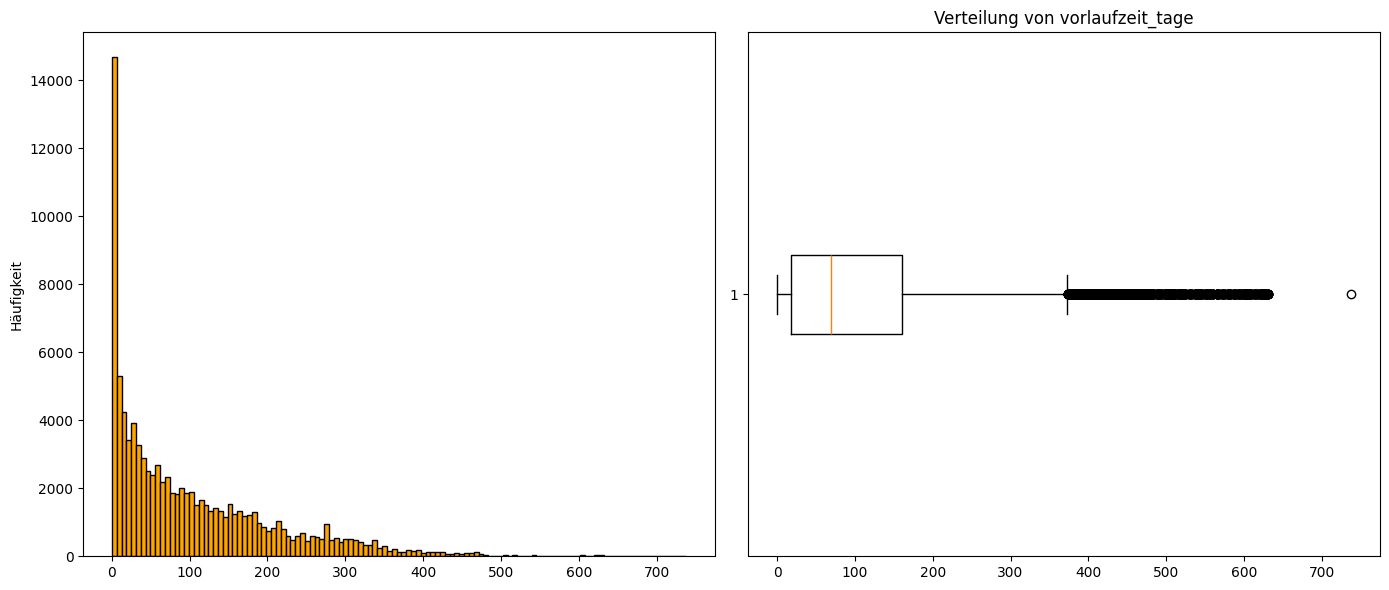

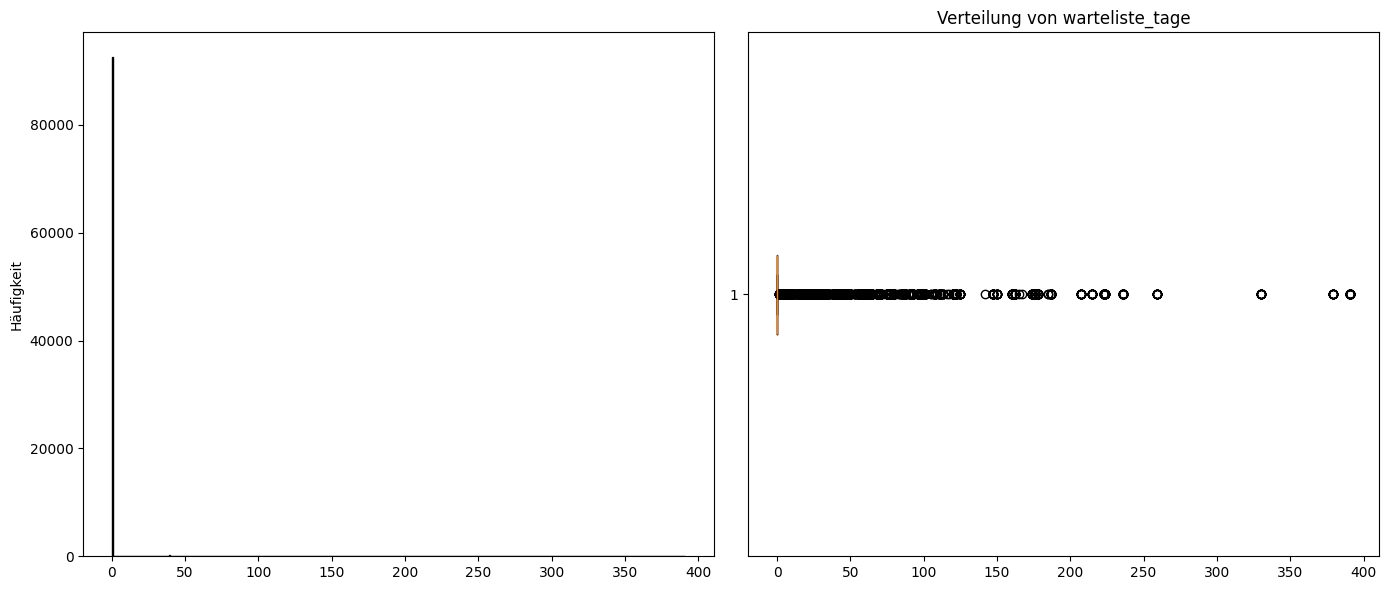

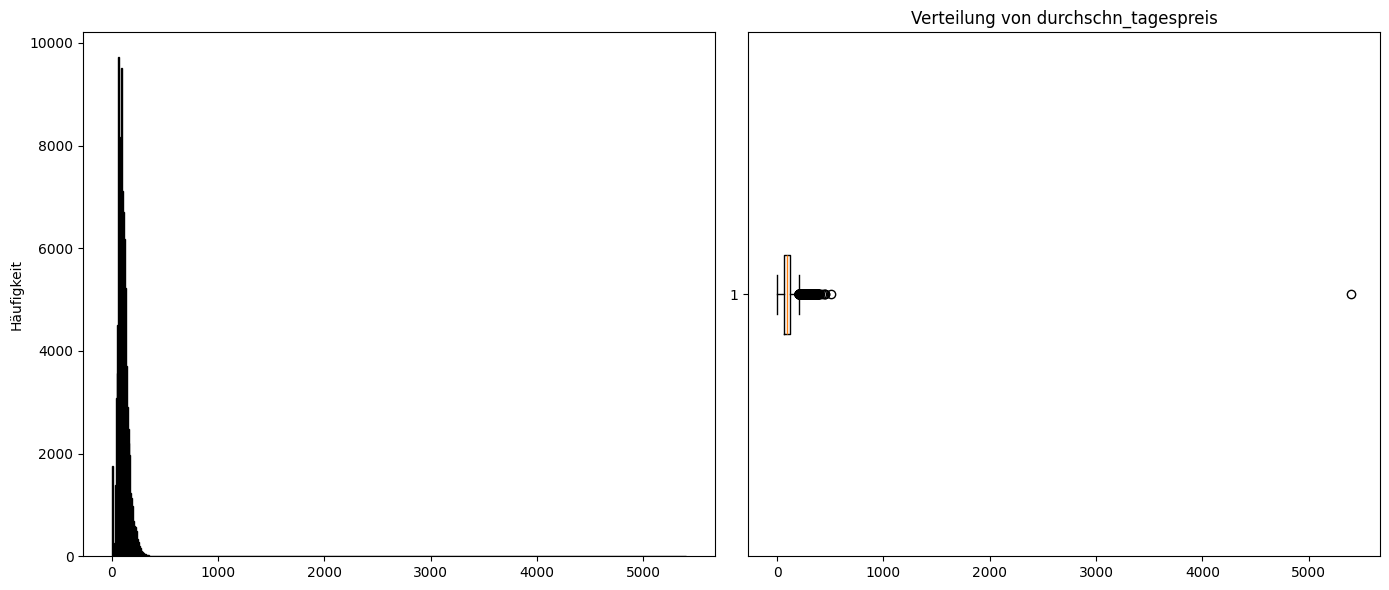

In [3]:
df = df_train.copy()

cancel_rate = float(df.loc[df["storniert"] == 1]["storniert"].count() / df["storniert"].count() * 100)

df_type = df[df["hotel_typ"] == "Ferienhotel"]
cancel_rate_holiday = float(df_type[df["storniert"] == 1]["storniert"].count() / df_type["storniert"].count() * 100)

df_type = df[df["hotel_typ"] == "Stadthotel"]
cancel_rate_city = float(df_type[df["storniert"] == 1]["storniert"].count() / df_type["storniert"].count() * 100)

df_type = df[df["vorlaufzeit_tage"] == 0]
cancel_rate_vorlaufzeit = float(df_type[df["storniert"] == 1]["storniert"].count() / df_type["storniert"].count() * 100)

df_type = df[df["vorlaufzeit_tage"] < 5]
cancel_rate_recent_resv = float(df_type[df["storniert"] == 1]["storniert"].count() / df_type["storniert"].count() * 100)

print(
    f"Stornierungsraten:\n"
    f"Gesamt:                  {cancel_rate:.2f} %\n"
    f"Ferienhotel:             {cancel_rate_holiday:.2f} %\n"
    f"Stadthotel:              {cancel_rate_city:.2f} %\n"
    f"Buchungen vor Ort:       {cancel_rate_vorlaufzeit:.2f} %\n"
    f"Kurzfristige Buchungen:  {cancel_rate_recent_resv:.2f} %"
)

# TODO: Auswahl von Spalten zum plotten
# for column in df.select_dtypes(include=np.number).columns.drop(["storniert", "stammgast", "agentur_id"]):
for column in ["vorlaufzeit_tage", "warteliste_tage", "durchschn_tagespreis"]:
    _, axes = plt.subplots(1, 2, figsize=(14, 6))

    axes[0].hist(df[column].dropna(), bins="auto", color="orange", edgecolor="black")
    axes[0].set_ylabel("Häufigkeit")

    axes[1].boxplot(df[column].dropna(), vert=False)

    plt.title(f"Verteilung von {column}")
    plt.tight_layout()
    plt.show()

# (2 / 3) Vorverarbeitung und Feature Engineering

In [4]:
# Anzahl Feiertage im Buchungszeitraum
df_holidays = pd.read_csv("data/portugal_feiertage.csv")
df_holidays["datum"] = pd.to_datetime(df_holidays["datum"])
df_holidays = df_holidays.set_index("datum")


def map_holidays(df: pd.DataFrame) -> pd.DataFrame:
    """Berechnet die Anzahl an Feiertage innerhalb eines Buchungszeitraumes als neues Feature."""
    df = df.copy()
    df["abreisedatum"] = df["anreisedatum"] + pd.to_timedelta((df["naechte_wochenende"] + df["naechte_wochentag"]), unit="D")

    df["anzahl_feiertage"] = 0
    for d in df_holidays.index:
        df["anzahl_feiertage"] += ((df["anreisedatum"] <= d) & (df["abreisedatum"] >= d)).astype(int)

    return df.drop(columns=["abreisedatum"])

In [5]:
N_GRUPPEN = 5
MIN_BUCHUNGEN = 20
RISIKO_GRENZEN = [0.0, 0.20, 0.35, 0.50, 0.70, 1.0]  # TODO: Eigene Gruppe für Rate = 0?


def get_cancel_rates(df: pd.DataFrame, column: str, min_buchungen: int = MIN_BUCHUNGEN) -> pd.DataFrame:
    df = df.copy()
    df["agentur_id"] = df["agentur_id"].astype(dtype="Int64")  # Agenturen sind fälschlich als float gespeichert
    rates = df.groupby(column)["storniert"].agg(["mean", "count"]).rename(columns={"mean": "stornierungsrate", "count": "anzahl"})
    return rates[rates["anzahl"] >= min_buchungen]


def assign_risk_groups(rates: pd.DataFrame, n_gruppen: int = N_GRUPPEN) -> pd.Series:
    return pd.cut(
        rates["stornierungsrate"],
        bins=RISIKO_GRENZEN,
        labels=list(range(N_GRUPPEN)),
        include_lowest=True,
    ).astype(int)

In [6]:
import matplotlib.patches as mpatches

RISIKO_FARBEN = ["green", "yellow", "orange", "red", "purple"]
RISIKO_LABELS = ["Niedrig", "Mittel-niedrig", "Mittel-hoch", "Hoch", "Sehr-hoch"]


def plot_cancel_rate_risk_groups(df: pd.DataFrame) -> None:
    land_rates = get_cancel_rates(df, "herkunftsland")
    agentur_rates = get_cancel_rates(df, "agentur_id")

    land_rates["risikogruppe"] = assign_risk_groups(land_rates)
    agentur_rates["risikogruppe"] = assign_risk_groups(agentur_rates)

    # Legende mit Prozenzbereichen
    legend_patches = [
        mpatches.Patch(
            facecolor=RISIKO_FARBEN[i],
            edgecolor="gray",
            linewidth=0.5,
            label=f"Gruppe {i} – {RISIKO_LABELS[i]}  ({RISIKO_GRENZEN[i]:.0%}–{min(RISIKO_GRENZEN[i + 1], 1.0):.0%})",
        )
        for i in range(N_GRUPPEN)
    ]

    for rates, titel_base in [
        (land_rates, "Herkunftsland"),
        (agentur_rates, "Agentur-ID"),
    ]:
        n = len(rates)
        fig, (ax_hist, ax_bars) = plt.subplots(
            1,
            2,
            figsize=(18, 10),
        )
        fig.suptitle(f"Stornierungsraten – {titel_base}", fontsize=13)

        # 1. Plot: Häufigkeitsverteilung der Stonierungsraten
        _, bin_edges, patches = ax_hist.hist(
            rates["stornierungsrate"],
            bins=20,
            edgecolor="black",
            linewidth=0.4,
        )
        bin_width = bin_edges[1] - bin_edges[0]

        # Bins nach Risikogruppe einfärben
        for patch, left in zip(patches, bin_edges[:-1]):
            midpoint = left + bin_width / 2
            gruppe = pd.cut(
                [midpoint],
                bins=RISIKO_GRENZEN,
                labels=list(range(N_GRUPPEN)),
                include_lowest=True,
            )[0]
            patch.set_facecolor(RISIKO_FARBEN[int(gruppe)] if pd.notna(gruppe) else "lightgray")

        # Linie für Mittelwert und Median
        stat_handles = [
            plt.Line2D([0], [0], color="red", linestyle="--", linewidth=1.5, label=f"Mittelwert ({rates['stornierungsrate'].mean():.1%})"),
            plt.Line2D([0], [0], color="black", linestyle=":", linewidth=1.5, label=f"Median ({rates['stornierungsrate'].median():.1%})"),
        ]
        ax_hist.axvline(rates["stornierungsrate"].mean(), color="red", linestyle="--", linewidth=1.5)
        ax_hist.axvline(rates["stornierungsrate"].median(), color="black", linestyle=":", linewidth=1.5)

        ax_hist.set_xlabel("Stornierungsrate")
        ax_hist.set_xlim(0, 1)
        ax_hist.set_ylabel("Anzahl Gruppen")
        ax_hist.set_title(f"Häufigkeitsverteilung  (n={n}, >={MIN_BUCHUNGEN} Buchungen)")
        ax_hist.legend(handles=legend_patches + stat_handles, fontsize=7.5, loc="upper right")

        # 2. Plot: Gruppen sortiert nach Stornierungsrate
        sorted_rates = rates.sort_values("stornierungsrate", ascending=True)
        bar_colors = [RISIKO_FARBEN[g] for g in sorted_rates["risikogruppe"]]

        ax_bars.barh(
            sorted_rates.index.astype(str),
            sorted_rates["stornierungsrate"],
            color=bar_colors,
            edgecolor="black",
            linewidth=0.5,
            height=1,  # Balkenbreite
        )

        # Whitespace oben/unten entfernen
        ax_bars.set_ylim(-0.5, n - 0.5)

        ax_bars.set_xlabel("Stornierungsrate")
        ax_bars.set_xlim(0, 1)
        ax_bars.set_title(f"Alle {n} Gruppen – sortiert nach Stornierungsrate")
        ax_bars.tick_params(axis="y", labelsize=max(5, min(8, 350 / n)))
        ax_bars.legend(handles=legend_patches, fontsize=7.5, loc="upper right")

        plt.tight_layout()
        plt.show()

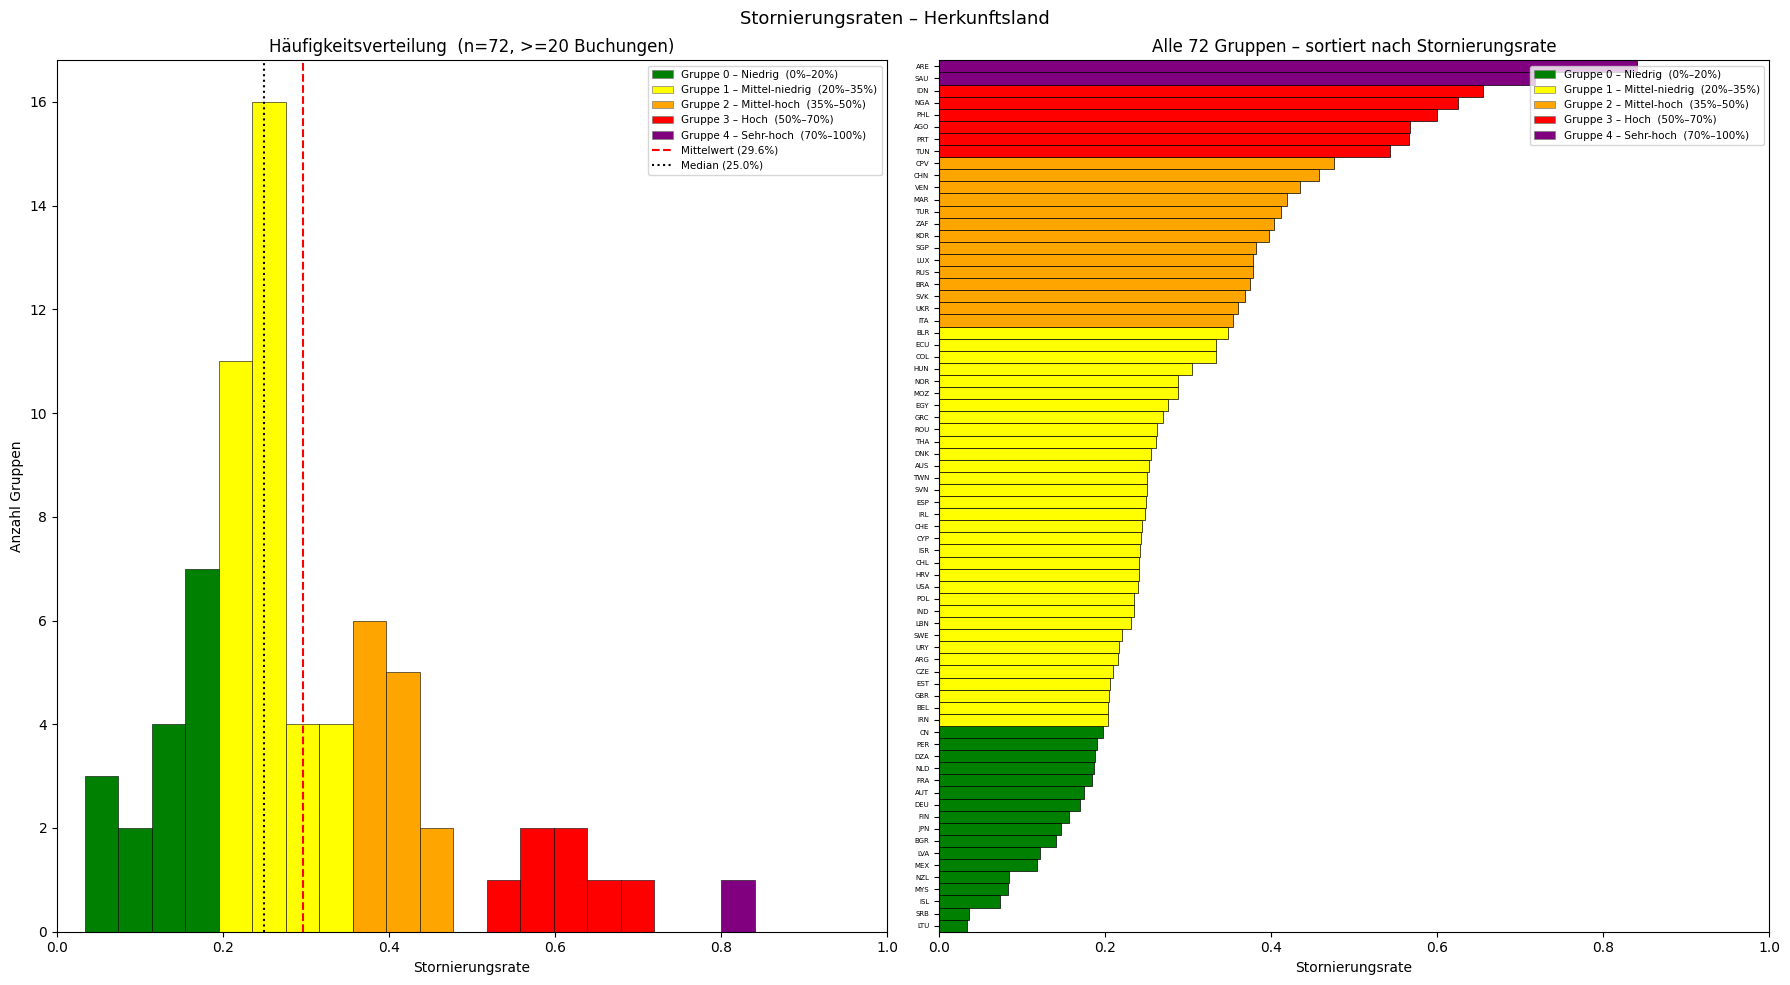

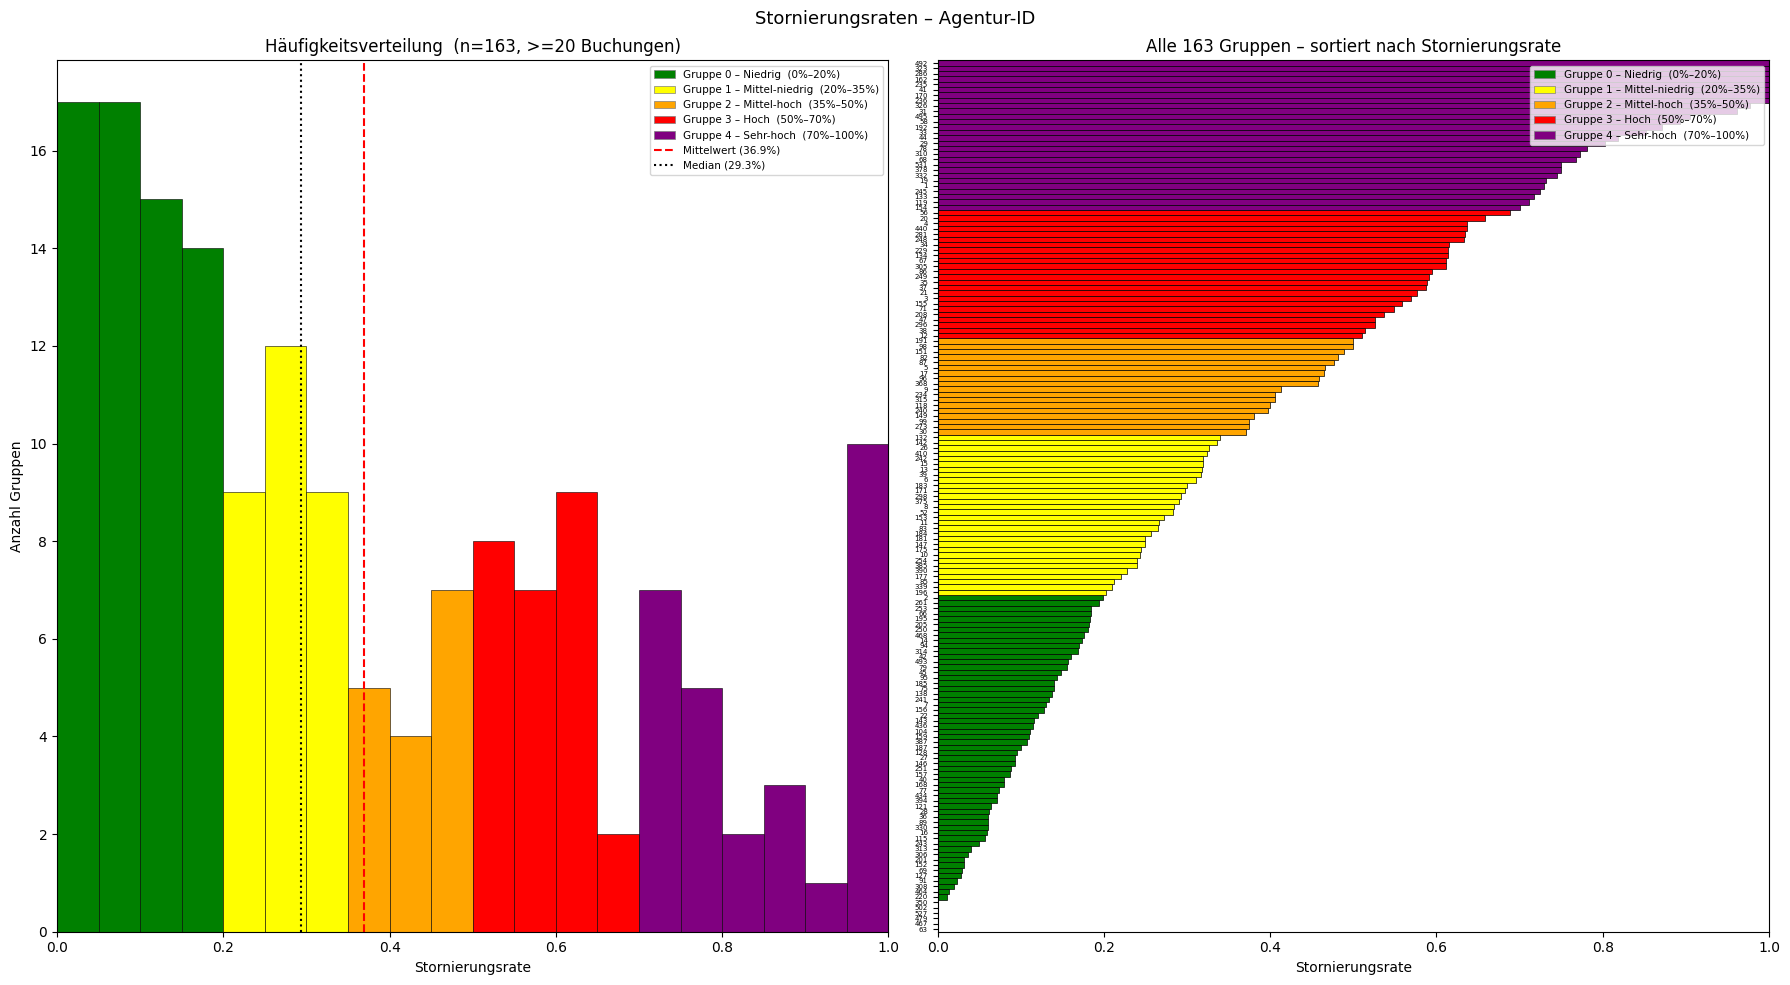

In [7]:
plot_cancel_rate_risk_groups(df_train)

In [8]:
UNBEKANNTE_RISIKOGRUPPE = 0  # Niedrigstes Risiko TODO: Eigene Gruppe?

herkunftsland_mapping: dict = assign_risk_groups(get_cancel_rates(df_train, "herkunftsland")).to_dict()
agentur_mapping: dict = assign_risk_groups(get_cancel_rates(df_train, "agentur_id")).to_dict()


def features(df: pd.DataFrame, drop: list | None = None) -> pd.DataFrame:
    """Generiert oder transformiert neue Features."""
    drop = [] if drop is None else drop
    df = df.copy()

    df["anreisedatum"] = pd.to_datetime(df["anreisedatum"])
    df["stammgast"] = df["stammgast"].astype(str)  # Stammgast ist kategorisch
    df["agentur_id"] = df["agentur_id"].astype(dtype="Int64")  # Agenturen sind fälschlich als float gespeichert

    df["herkunftsland_risiko"] = df["herkunftsland"].map(herkunftsland_mapping).fillna(UNBEKANNTE_RISIKOGRUPPE).astype(int)
    df["agentur_risiko"] = df["agentur_id"].map(agentur_mapping).fillna(UNBEKANNTE_RISIKOGRUPPE).astype(int)

    # Buchungen direkt vor Ort haben eine geringe Stornierungsrate
    # TODO: Ist dies tatsächlich sinnvoll, wenn z.B. 0 < vorlaufzeit_tage < 5 die gleiche Rate hat (+1%)
    # Damit wäre "Buchung vor Ort" kein Sonderfall, und damit redundant?
    # Vielleicht eher "kurzfristige_buchungen" als Feature, mit vorlaufzeit < 10 oder ähnlich
    df["buchung_vor_ort"] = (df["vorlaufzeit_tage"] == 0).astype(int)

    df["zimmer_geaendert"] = (df["gebuchter_zimmertyp"] != df["zugewiesener_zimmertyp"]).astype(int)

    # Additive Glättung verhindert unnütze extreme Raten (wie 1 Stornierung/1 Gesamt => 100%)
    df["frueh_stornierungsrate"] = (df["frueh_stornierungen"] + 2) / (df["frueh_stornierungen"] + df["frueh_buchungen_eingehalten"] + 2 * 2)

    df = map_holidays(df)

    return df.drop(
        columns=[
            *drop,
            "anreisedatum",
            "herkunftsland",
            "agentur_id",
            "gebuchter_zimmertyp",
            "zugewiesener_zimmertyp",
            "frueh_stornierungen",
            "frueh_buchungen_eingehalten",
            "buchungskanal",  # buchungskanal zeigt hohe Korrelation zu Marksegment
        ]
    )

In [9]:
from sklearn.model_selection import train_test_split

# Duplizierte Datenpunkte entfernen (hier vor dem Split)
print(f"Anzahl Duplikate: {df_train.duplicated().sum()}")
df_train = df_train.drop_duplicates()

# Entfernen von nicht relevanten Spalten
df_train = features(df_train, ["reservierungsstatus", "reservierungsstatus_datum"])

# Im Folgendem wird nur noch der Trainingsdatensatz betrachtet um Data Leakage zu vermeiden
X_train, X_valid, y_train, y_valid = train_test_split(
    df_train.drop(columns=["storniert"]),
    df_train["storniert"],
    test_size=0.2,
    random_state=42,
)

categorical = X_train.select_dtypes(exclude=np.number).columns
numerical = X_train.select_dtypes(include=np.number).columns

Anzahl Duplikate: 286


In [10]:
# Ausgabe kategorischer Features
print(f"Kategorische Features ({len(categorical)}):\n")
for col in categorical:
    n_unique = X_train[col].nunique()
    print(f"{col:25} {n_unique:5} eindeutige Werte")

display("Trainingsdatensatz (kategorische Features):", X_train[categorical])

# Spalten die fehlende Werte enthalten ausgeben
missing = X_train.isna().sum()
display("Spalten mit fehlenden Werten:", missing[missing > 0])

# Ausreißern veranschaulichen
display(
    "Verteilung numerischer Features:",
    X_train.select_dtypes(include=np.number).describe(percentiles=[0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.995, 0.999]),
)

Kategorische Features (6):

hotel_typ                     2 eindeutige Werte
verpflegung                   5 eindeutige Werte
marktsegment                  8 eindeutige Werte
stammgast                     2 eindeutige Werte
anzahlungsart                 3 eindeutige Werte
kundentyp                     4 eindeutige Werte


'Trainingsdatensatz (kategorische Features):'

,hotel_typ,verpflegung,marktsegment,stammgast,anzahlungsart,kundentyp
76374,Stadthotel,Frühstück,Online Reisebüro,0,Ohne Anzahlung,Einzelbucher
66460,Stadthotel,Frühstück,Direktbuchung,0,Ohne Anzahlung,Einzelbucher
82131,Stadthotel,Frühstück,Offline Reisebüro,0,Ohne Anzahlung,Einzelbucher
44586,Stadthotel,Frühstück,Online Reisebüro,0,Ohne Anzahlung,Einzelbucher
49014,Stadthotel,Frühstück,Direktbuchung,0,Ohne Anzahlung,Einzelbucher
...,...,...,...,...,...,...
6277,Ferienhotel,Frühstück,Online Reisebüro,0,Ohne Anzahlung,Einzelbucher
55072,Stadthotel,Frühstück,Online Reisebüro,0,Ohne Anzahlung,Einzelbucher
77084,Stadthotel,Frühstück,Offline Reisebüro,0,Ohne Anzahlung,Einzelbucher
860,Ferienhotel,Frühstück,Online Reisebüro,0,Ohne Anzahlung,Einzelbucher


'Spalten mit fehlenden Werten:'

kinder    3
dtype: int64

'Verteilung numerischer Features:'

,vorlaufzeit_tage,naechte_wochenende,naechte_wochentag,erwachsene,kinder,babys,buchungsaenderungen,warteliste_tage,durchschn_tagespreis,parkplaetze_benoetigt,anzahl_sonderwuensche,herkunftsland_risiko,agentur_risiko,buchung_vor_ort,zimmer_geaendert,frueh_stornierungsrate,anzahl_feiertage
count,76180.000000,76180.000000,76180.000000,76180.000000,76177.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000,76180.000000
mean,103.834602,0.929942,2.498307,1.858112,0.103260,0.007981,0.220924,2.293712,101.953647,0.062930,0.574587,1.687845,1.510186,0.046495,0.124390,0.499894,0.176424
std,106.767568,0.998556,1.911787,0.584068,0.397326,0.101392,0.655072,17.337603,51.788280,0.247444,0.794688,1.207139,1.270517,0.210556,0.330028,0.044111,0.411521
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.055556,0.000000
5%,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,38.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000
10%,3.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,50.609000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.500000,0.000000
25%,18.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,69.310000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.500000,0.000000
50%,69.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,94.470000,0.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.500000,0.000000
75%,160.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,125.900000,0.000000,1.000000,3.000000,2.000000,0.000000,0.000000,0.500000,0.000000
90%,264.100000,2.000000,5.000000,2.000000,0.000000,0.000000,1.000000,0.000000,164.211000,0.000000,2.000000,3.000000,3.000000,0.000000,1.000000,0.500000,1.000000


'Korrelation der numerischen Features mit storniert:'

storniert                 1.000000
agentur_risiko            0.360981
herkunftsland_risiko      0.344718
vorlaufzeit_tage          0.291703
frueh_stornierungsrate    0.237872
erwachsene                0.059906
warteliste_tage           0.051933
durchschn_tagespreis      0.044816
anzahl_feiertage          0.035741
naechte_wochentag         0.024607
kinder                    0.008338
naechte_wochenende        0.001288
babys                    -0.031539
buchung_vor_ort          -0.131794
buchungsaenderungen      -0.141515
parkplaetze_benoetigt    -0.194634
anzahl_sonderwuensche    -0.235324
zimmer_geaendert         -0.246174
Name: storniert, dtype: float64

'Korrelation der kategorischen Features mit storniert:'

storniert                         1.000000
anzahlungsart_Nicht erstattbar    0.478201
marktsegment_Gruppen              0.219147
hotel_typ_Stadthotel              0.132513
verpflegung_Vollpension           0.035267
marktsegment_Unbekannt            0.006695
verpflegung_Ohne Verpflegung      0.001749
marktsegment_Online Reisebüro    -0.003725
marktsegment_Luftfahrt           -0.012828
verpflegung_Halbpension          -0.021611
kundentyp_Vertrag                -0.023124
verpflegung_Unbekannt            -0.027090
marktsegment_Offline Reisebüro   -0.030156
kundentyp_Gruppe                 -0.035711
marktsegment_Kulanz              -0.037655
marktsegment_Firmenbuchung       -0.082577
stammgast_1                      -0.085535
kundentyp_Gruppenbucher          -0.125998
anzahlungsart_Ohne Anzahlung     -0.474224
Name: storniert, dtype: float64

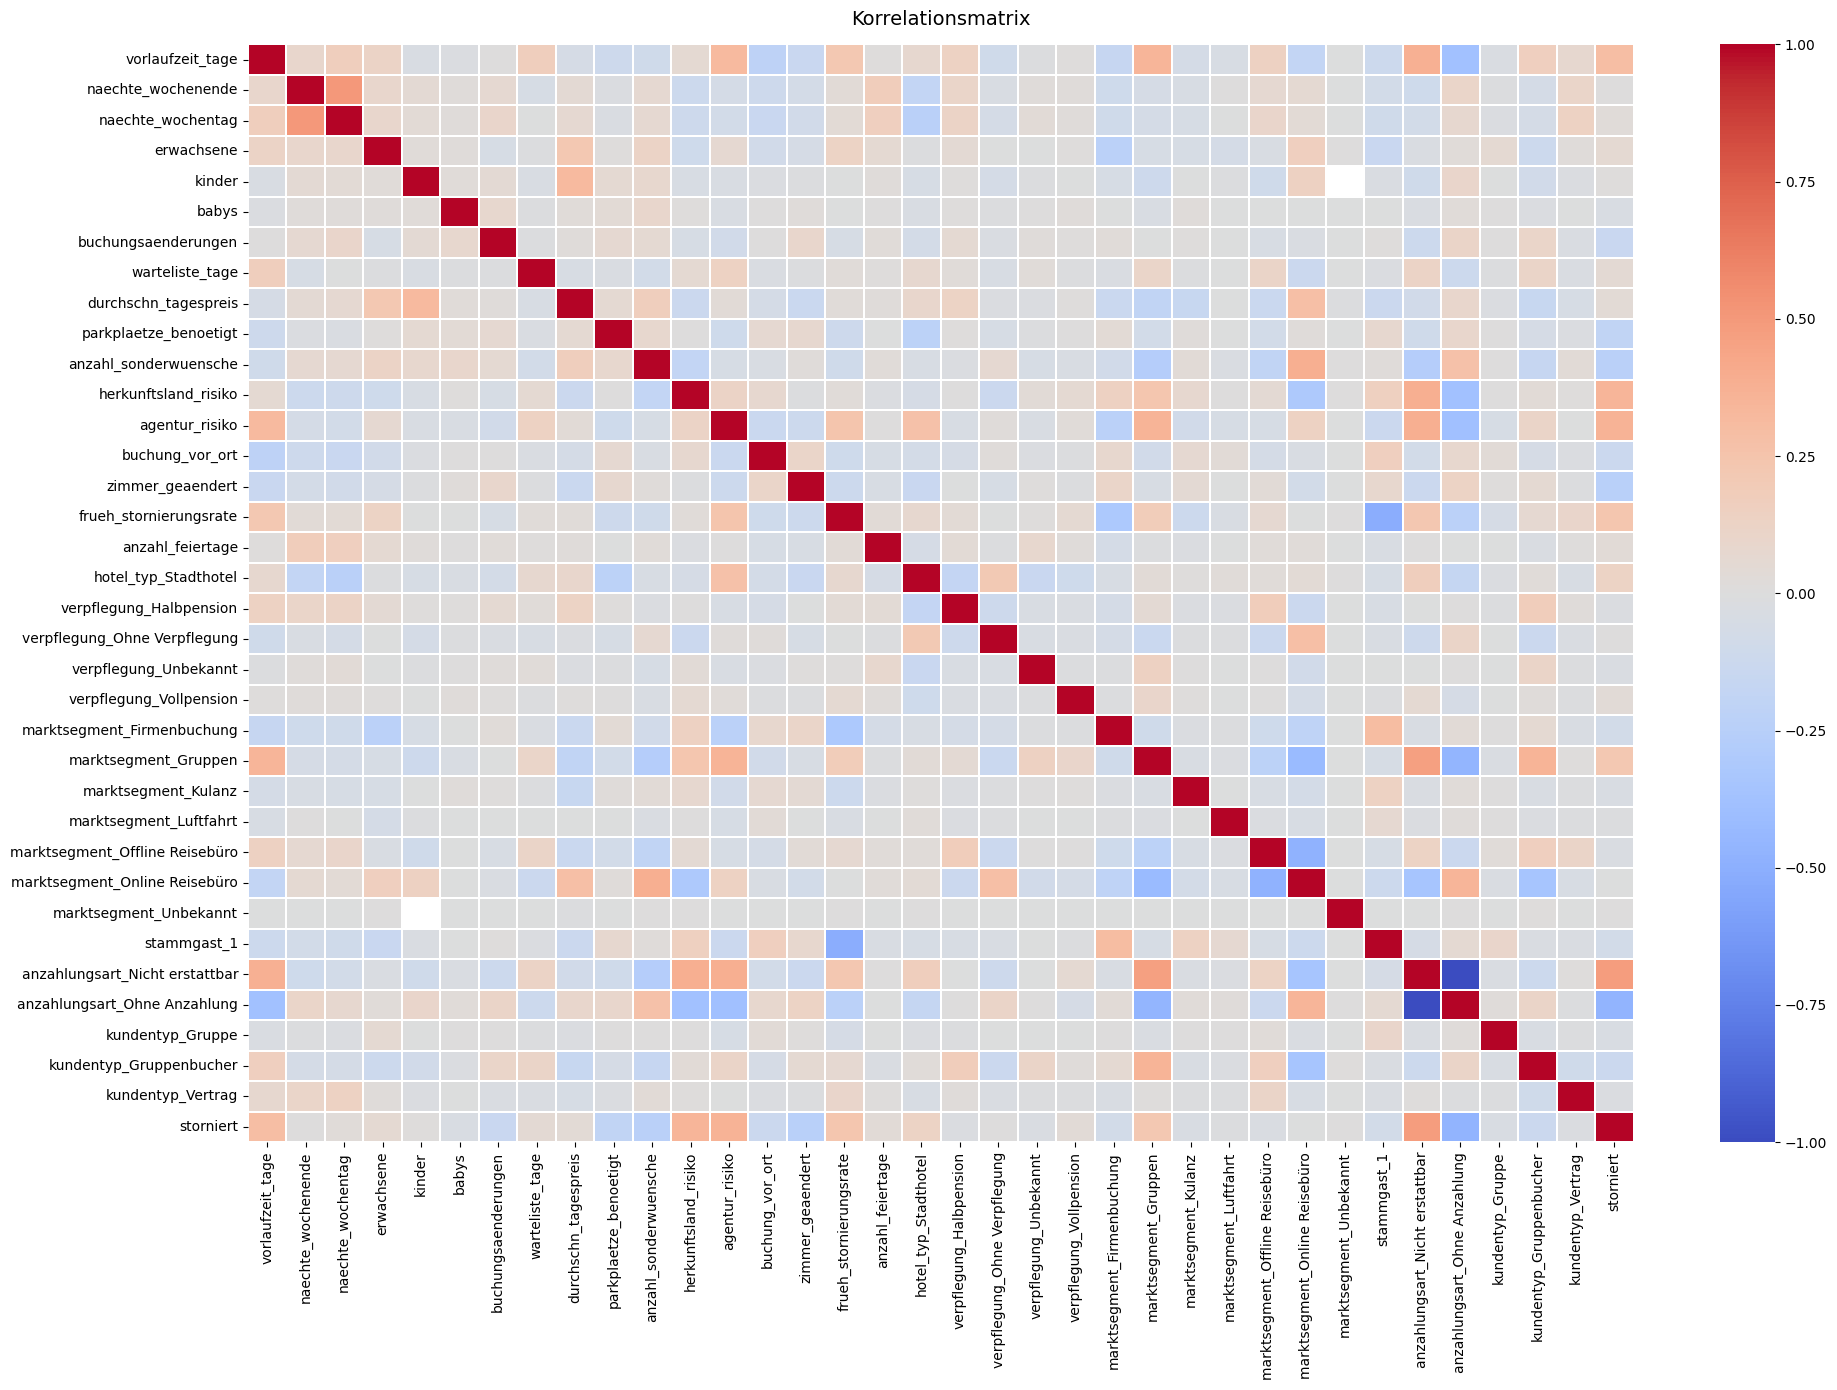

In [11]:
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder


def show_correlations(df: pd.DataFrame, target: pd.DataFrame, text: str) -> None:
    """Ausgabe der Korrelationen."""
    df_corr = df.copy()
    df_corr["storniert"] = target.copy()

    correlations = df_corr.corr()
    display(text, correlations["storniert"].sort_values(ascending=False))


show_correlations(X_train[numerical], y_train, "Korrelation der numerischen Features mit storniert:")

encoding = OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop="first")

# TODO: Entfernen nach Behandlung
# categorical = categorical.drop("agentur_id")  # TODO: Agentur in Risikogruppen unterteilen
df_encoded = encoding.fit_transform(X=X_train[categorical])
df_encoded = pd.DataFrame(df_encoded, columns=encoding.get_feature_names_out(), index=X_train.index)

show_correlations(df_encoded, y_train, "Korrelation der kategorischen Features mit storniert:")

# Korrelationsmatrix der Features
df_heatmap = pd.concat([X_train[numerical], df_encoded], axis=1)
df_heatmap["storniert"] = y_train

_, ax = plt.subplots(figsize=(20, 14))
sns.heatmap(
    df_heatmap.corr(),
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.3,
    annot=False,
    ax=ax,
)
plt.title("Korrelationsmatrix", fontsize=14, pad=14)
plt.tight_layout()
plt.show()

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler


def clip_numericals(X: np.ndarray) -> np.ndarray:
    """Behandlung von Ausreißern."""
    upper = np.percentile(X, 99, axis=0)

    return np.clip(X, 0, upper)


numerical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="constant", fill_value=0.0)),  # Kinder (keine Angabe = keine Kinder)
        ("clip", FunctionTransformer(clip_numericals, validate=False)),
        ("scaler", StandardScaler()),  # Für logistische Regression
    ]
)

categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="constant", fill_value="Keine Angabe")),  # Herkunftsland und Agenturen
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer([("num", numerical_pipeline, numerical), ("cat", categorical_pipeline, categorical)])

# (4) Training der Modelle

In [13]:
import gurobipy as gp
from gurobipy import GRB


def optimize_threshold_gurobi(y_true: pd.Series, y_prob: pd.Series, df_features: pd.DataFrame) -> tuple[float, float]:
    """Minimiert Gesamtkosten und berechnet Schwellwert."""
    aufenthaltsdauer = df_features["naechte_wochenende"] + df_features["naechte_wochentag"]
    fn_kosten = (df_features["durchschn_tagespreis"] * aufenthaltsdauer * 0.9).values

    true_values = y_true.values
    vorhersage_wahrscheinlichkeit = y_prob # Vorhergesagte Stonierungswahrscheinlichkeit
    anzahl_buchungen = len(true_values)

    env = gp.Env(empty=True)
    env.setParam("OutputFlag", 0)
    env.start()
    model = gp.Model("Threshold_Optimierung", env=env)

    threshold = model.addVar(vtype=GRB.CONTINUOUS, lb=0.0, ub=1.0, name="threshold")
    vorhersage = model.addVars(anzahl_buchungen, vtype=GRB.BINARY, name="z")

    M = 1.01 # Muss größer als max|p_i - t| = 1 sein
    eps = 1e-5 # verhindert Gleichheit bei p_i == t

    # Nebenbedingungen: legen fest, ob Vorhersage als stoniert oder nicht stoniert erfasst werden soll. 
    for i in range(anzahl_buchungen):
        model.addConstr(vorhersage_wahrscheinlichkeit[i] - threshold >= -M * (1 - vorhersage[i]), name=f"lower_{i}") 
        model.addConstr(vorhersage_wahrscheinlichkeit[i] - threshold <= M * vorhersage[i] - eps, name=f"upper_{i}")

    gesamtkosten = gp.LinExpr()
    for i in range(anzahl_buchungen):
        if true_values[i] == 0:
            gesamtkosten += 250.0 * vorhersage[i]
        else:
            gesamtkosten += fn_kosten[i] * (1 - vorhersage[i])

    model.setObjective(gesamtkosten, GRB.MINIMIZE)
    model.optimize()

    if model.status == GRB.OPTIMAL:
        return model.ObjVal, threshold.X
    raise ValueError("Gurobi konnte keine optimale Lösung finden.")

In [14]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score
from sklearn.model_selection import GridSearchCV


def show_metrics(y_true: pd.DataFrame, y_pred: pd.DataFrame, title: str = "") -> None:
    """Ausgabe der relevanten Metriken."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    print(
        f"{title}\n"
        f"Accuracy:             {accuracy_score(y_true, y_pred) * 100:.7f}\n"
        f"Precision:            {precision_score(y_true, y_pred) * 100:.7f}\n"
        f"Recall:               {recall_score(y_true, y_pred) * 100:.7f}\n"
        f"False positive rate:  {fp / (fp + tn) * 100:.7f}\n"
    )


def show_feature_importances(model, name: str) -> None:
    """Ausgabe der Feature Importances."""
    onehot = model.named_steps["preprocessor"].named_transformers_["cat"].named_steps["onehot"]
    feature_names_cat = onehot.get_feature_names_out(categorical)

    feature_names = numerical.tolist() + feature_names_cat.tolist()

    # Wichtigkeit der Features beim splitten
    importances = model.named_steps[name].feature_importances_

    df_importances = pd.DataFrame({"feature": feature_names, "importance": importances}).sort_values("importance", ascending=False)

    display("Feature Importances:", df_importances)


def show_permutation_importances(model) -> None:
    """Ausgabe der Permutation Importances."""
    result = permutation_importance(model, X_train, y_train, n_repeats=10, random_state=42, scoring="accuracy")

    df_importances = pd.DataFrame({"feature": X_train.columns, "importance": result.importances_mean}).sort_values("importance", ascending=False)

    display("Permutation Importances:", df_importances)


def evaluate_model(name: str, ident: str, search: GridSearchCV, output_importances: list[bool] = [False, False]) -> dict:
    """Ausgabe Modellergebnisse und Rückgabe Dictionary mit wichtigsten Parametern."""
    best_model = search.best_estimator_

    y_pred = best_model.predict(X_train)
    show_metrics(y_train, y_pred, title=f"{name} (Trainingsdaten)")

    df = X_train.copy()
    df["fehler"] = abs(y_pred - y_train)
    display(df.groupby("hotel_typ")["fehler"].describe())

    y_pred = best_model.predict(X_valid)
    show_metrics(y_valid, y_pred, title=f"{name} (Validationsdaten)")

    display("Beste Parameter:", search.best_params_)

    if output_importances[0]:
        show_feature_importances(best_model, ident)
    if output_importances[1]:
        show_permutation_importances(best_model)

    y_prob = best_model.predict_proba(X_valid)[:, 1] # Gurobi braucht die Wahrscheinlichkeiten wie das Modell "stoniert" als Klasse einschätzt
    costs, threshold = optimize_threshold_gurobi(y_valid, y_prob, X_valid)
    # costs, threshold = 0, 0

    tn, fp, fn, tp = confusion_matrix(y_valid, y_pred).ravel()

    return {
        name: {
            "Model": best_model,
            "Parameter": search.best_params_,
            "Accuracy": round(accuracy_score(y_valid, y_pred) * 100, 2),
            "Precision": round(precision_score(y_valid, y_pred) * 100, 2),
            "Recall": round(recall_score(y_valid, y_pred) * 100, 2),
            "False positive rate": round(fp / (fp + tn) * 100, 2),
            "Gesamtkosten": costs,
            "Schwellwert": threshold,
        }
    }


models = []

In [15]:
def model_by_hotels(name: str, search: GridSearchCV):
    X_t = X_train.copy()
    X_v = X_valid.copy()

    X_t["storniert"] = y_train
    X_v["storniert"] = y_valid

    X_t["pred"] = None
    X_v["pred"] = None
    X_v["prob"] = np.nan

    models = {}

    for hotel_type in ["Stadthotel", "Ferienhotel"]:
        # Filtern von Trainingsdaten
        train_filtered = X_t[X_t["hotel_typ"] == hotel_type].copy()

        y_train_h = train_filtered["storniert"]
        X_train_h = train_filtered.drop(columns=["storniert", "pred"])

        # Filtern von Validationsdaten
        valid_filtered = X_v[X_v["hotel_typ"] == hotel_type].copy()

        X_valid_h = valid_filtered.drop(columns=["storniert", "pred"])

        search.fit(X_train_h, y_train_h)

        model = search.best_estimator_
        models[hotel_type] = model

        # Vorhersagen mit vollständigem Datensatz zusammenführen
        y_pred = model.predict(X_train_h)
        X_t.loc[train_filtered.index, "pred"] = y_pred

        y_pred = model.predict(X_valid_h)
        X_v.loc[valid_filtered.index, "pred"] = y_pred

        y_prob = model.predict_proba(X_valid_h)[:, 1]
        X_v.loc[valid_filtered.index, "prob"] = y_prob

    show_metrics(y_train, X_t["pred"].astype(int), f"{name} (Trainingsdaten)")
    show_metrics(y_valid, X_v["pred"].astype(int), f"{name} (Validationsdaten)")

    y_pred = X_v["pred"].astype(int)
    y_prob = X_v["prob"].values

    costs, threshold = optimize_threshold_gurobi(y_valid, y_prob, X_valid)
    # costs, threshold = 0, 0

    tn, fp, fn, tp = confusion_matrix(y_valid, y_pred).ravel()

    return {
        name: {
            "Model": models,
            "Parameter": None,
            "Accuracy": round(accuracy_score(y_valid, y_pred) * 100, 2),
            "Precision": round(precision_score(y_valid, y_pred) * 100, 2),
            "Recall": round(recall_score(y_valid, y_pred) * 100, 2),
            "False positive rate": round(fp / (fp + tn) * 100, 2),
            "Gesamtkosten": costs,
            "Schwellwert": threshold,
        }
    }

In [16]:
from sklearn.tree import DecisionTreeClassifier


def model_decision_tree(param_grid: dict):
    return GridSearchCV(
        estimator=Pipeline([("preprocessor", preprocessor), ("tree", DecisionTreeClassifier(random_state=42))]),
        param_grid=param_grid,
        scoring="accuracy",
        cv=CV,
        n_jobs=N_JOBS,
        verbose=VERBOSE,
    )


# Training auf ganzen Trainingsdatensatz
parameters = {
    "tree__max_depth": [5, 8, 10, 12, 15],
    "tree__min_samples_split": [20, 50, 100, 200],
    "tree__min_samples_leaf": [10, 20, 50],
    "tree__criterion": ["gini", "entropy"],
}

search = model_decision_tree(parameters)
search.fit(X_train, y_train)

models.append(evaluate_model("Entscheidungsbaum", "tree", search, [True, False]))

# Training getrennt nach Hotels
parameters = {
    "tree__max_depth": [5, 8, 10, 12],
    "tree__min_samples_split": [20, 50, 100, 200],
    "tree__min_samples_leaf": [20, 50, 100],
    "tree__criterion": ["gini", "entropy"],
}

search = model_decision_tree(parameters)
models.append(model_by_hotels("Entscheidungsbaum (getrennt)", search))

Fitting 5 folds for each of 120 candidates, totalling 600 fits
Entscheidungsbaum (Trainingsdaten)
Accuracy:             86.6907325
Precision:            85.2963094
Recall:               77.2904968
False positive rate:  7.8035885



,count,mean,std,min,25%,50%,75%,max
hotel_typ,,,,,,,,
Ferienhotel,25602.0,0.113038,0.316645,0.0,0.0,0.0,0.0,1.0
Stadthotel,50578.0,0.143244,0.350325,0.0,0.0,0.0,0.0,1.0


Entscheidungsbaum (Validationsdaten)
Accuracy:             85.7817915
Precision:            83.4107807
Recall:               76.6875534
False positive rate:  8.9071856



'Beste Parameter:'

{'tree__criterion': 'gini',
 'tree__max_depth': 15,
 'tree__min_samples_leaf': 10,
 'tree__min_samples_split': 100}

'Feature Importances:'

,feature,importance
35,anzahlungsart_Nicht erstattbar,0.376849
11,herkunftsland_risiko,0.110285
0,vorlaufzeit_tage,0.099997
12,agentur_risiko,0.096258
10,anzahl_sonderwuensche,0.062216
14,zimmer_geaendert,0.058560
9,parkplaetze_benoetigt,0.042364
39,kundentyp_Gruppenbucher,0.038729
15,frueh_stornierungsrate,0.026575
8,durchschn_tagespreis,0.022476


Fitting 5 folds for each of 96 candidates, totalling 480 fits
Fitting 5 folds for each of 96 candidates, totalling 480 fits
Entscheidungsbaum (getrennt) (Trainingsdaten)
Accuracy:             86.3888160
Precision:            85.0376622
Recall:               76.6330230
False positive rate:  7.8972566

Entscheidungsbaum (getrennt) (Validationsdaten)
Accuracy:             85.5402709
Precision:            83.0852713
Recall:               76.3172885
False positive rate:  9.0735196



In [17]:
from sklearn.linear_model import LogisticRegression

search = GridSearchCV(
    estimator=Pipeline([("preprocessor", preprocessor), ("logistic", LogisticRegression(random_state=42))]),
    param_grid={
        "logistic__C": [0.001, 0.01, 0.1, 1, 10, 100],
        "logistic__penalty": ["l2"],
        "logistic__solver": ["lbfgs"],
        "logistic__max_iter": [1000],
    },
    scoring="accuracy",
    cv=CV,
    n_jobs=N_JOBS,
    verbose=VERBOSE,
)

search.fit(X_train, y_train)

models.append(evaluate_model("Logistische Regression", "logistic", search))

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Logistische Regression (Trainingsdaten)
Accuracy:             82.6214229
Precision:            80.9506004
Recall:               69.2444381
False positive rate:  9.5437326



,count,mean,std,min,25%,50%,75%,max
hotel_typ,,,,,,,,
Ferienhotel,25602.0,0.151160,0.358212,0.0,0.0,0.0,0.0,1.0
Stadthotel,50578.0,0.185239,0.388495,0.0,0.0,0.0,0.0,1.0


Logistische Regression (Validationsdaten)
Accuracy:             82.8677938
Precision:            80.7761585
Recall:               70.2506408
False positive rate:  9.7638057



'Beste Parameter:'

{'logistic__C': 0.1,
 'logistic__max_iter': 1000,
 'logistic__penalty': 'l2',
 'logistic__solver': 'lbfgs'}

In [18]:
from sklearn.ensemble import RandomForestClassifier

search = GridSearchCV(
    estimator=Pipeline([("preprocessor", preprocessor), ("rf", RandomForestClassifier(random_state=42))]),
    param_grid={
        "rf__n_estimators": [300, 500],
        "rf__max_depth": [None],
        "rf__min_samples_split": [5, 10, 20],
        "rf__min_samples_leaf": [1, 2, 4],
        "rf__max_features": ["sqrt"],
    },
    scoring="accuracy",
    cv=CV,
    n_jobs=N_JOBS,
    verbose=VERBOSE,
)

search.fit(X_train, y_train)

models.append(evaluate_model("Random Forest", "rf", search))

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Random Forest (Trainingsdaten)
Accuracy:             97.6686794
Precision:            98.1585678
Recall:               95.4794228
False positive rate:  1.0490821



,count,mean,std,min,25%,50%,75%,max
hotel_typ,,,,,,,,
Ferienhotel,25602.0,0.021717,0.145761,0.0,0.0,0.0,0.0,1.0
Stadthotel,50578.0,0.024121,0.153427,0.0,0.0,0.0,0.0,1.0


Random Forest (Validationsdaten)
Accuracy:             88.1444923
Precision:            86.1018490
Recall:               80.9028767
False positive rate:  7.6264138



'Beste Parameter:'

{'rf__max_depth': None,
 'rf__max_features': 'sqrt',
 'rf__min_samples_leaf': 1,
 'rf__min_samples_split': 5,
 'rf__n_estimators': 300}

In [19]:
from sklearn.ensemble import GradientBoostingClassifier

search = GridSearchCV(
    estimator=Pipeline([("preprocessor", preprocessor), ("gb", GradientBoostingClassifier(random_state=42))]),
    param_grid={
        "gb__n_estimators": [100, 200],
        "gb__learning_rate": [0.05, 0.1, 0.2],
        "gb__max_depth": [3, 4, 5],
        "gb__subsample": [0.8, 1.0],
    },
    scoring="accuracy",
    cv=CV,
    n_jobs=N_JOBS,
    verbose=VERBOSE,
)

search.fit(X_train, y_train)

models.append(evaluate_model("Gradient Boosting", "gb", search))

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Gradient Boosting (Trainingsdaten)
Accuracy:             88.9695458
Precision:            86.8121619
Recall:               82.6995522
False positive rate:  7.3581450



,count,mean,std,min,25%,50%,75%,max
hotel_typ,,,,,,,,
Ferienhotel,25602.0,0.087064,0.281934,0.0,0.0,0.0,0.0,1.0
Stadthotel,50578.0,0.122069,0.327369,0.0,0.0,0.0,0.0,1.0


Gradient Boosting (Validationsdaten)
Accuracy:             87.0208968
Precision:            83.9450910
Recall:               80.1196240
False positive rate:  8.9487691



'Beste Parameter:'

{'gb__learning_rate': 0.2,
 'gb__max_depth': 5,
 'gb__n_estimators': 200,
 'gb__subsample': 1.0}

In [20]:
from sklearn.ensemble import StackingClassifier

search = GridSearchCV(
    estimator=Pipeline(
        [
            ("preprocessor", preprocessor),
            (
                "stack",
                StackingClassifier(
                    estimators=[
                        (
                            "tree",
                            DecisionTreeClassifier(
                                criterion="gini",
                                max_depth=15,
                                min_samples_split=100,
                                min_samples_leaf=10,
                                random_state=42,
                            ),
                        ),
                        (
                            "gb",
                            GradientBoostingClassifier(
                                n_estimators=200,
                                learning_rate=0.2,
                                max_depth=5,
                                subsample=1.0,
                                random_state=42,
                            ),
                        ),
                        (
                            "rf",
                            RandomForestClassifier(
                                n_estimators=300,
                                max_depth=None,
                                max_features="sqrt",
                                min_samples_leaf=1,
                                min_samples_split=5,
                                random_state=42,
                            ),
                        ),
                    ],
                    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
                    cv=2,  # intern: nur für Meta-Feature-Generierung, 2 reicht
                    n_jobs=N_JOBS,
                ),
            ),
        ]
    ),
    param_grid={
        "stack__final_estimator__C": [10, 100],
        "stack__final_estimator__penalty": ["l2"],
    },
    scoring="accuracy",
    cv=CV,
    n_jobs=N_JOBS,
    verbose=VERBOSE,
)

search.fit(X_train, y_train)

models.append(evaluate_model("Stacking", "stack", search))

Fitting 5 folds for each of 2 candidates, totalling 10 fits
Stacking (Trainingsdaten)
Accuracy:             95.7298504
Precision:            95.5819321
Recall:               92.7251404
False positive rate:  2.5103035



,count,mean,std,min,25%,50%,75%,max
hotel_typ,,,,,,,,
Ferienhotel,25602.0,0.037966,0.191117,0.0,0.0,0.0,0.0,1.0
Stadthotel,50578.0,0.045099,0.207523,0.0,0.0,0.0,0.0,1.0


Stacking (Validationsdaten)
Accuracy:             88.2232490
Precision:            85.6375839
Recall:               81.7715750
False positive rate:  8.0089820



'Beste Parameter:'

{'stack__final_estimator__C': 100, 'stack__final_estimator__penalty': 'l2'}

# (5) Evaluation

In [21]:
lowest_cost_model = min(models, key=lambda x: next(iter(x.values()))["Gesamtkosten"])

rows = []

for model in models:
    name, values = next(iter(model.items()))

    rows.append(
        {
            "name": name,
            "Gesamtkosten": values["Gesamtkosten"],
            "Schwellwert": values["Schwellwert"],
            "Accuracy": values["Accuracy"],
            "Precision": values["Precision"],
            "Recall": values["Recall"],
            "False positive rate": values["False positive rate"],
        }
    )

df_models = pd.DataFrame(rows)
df_models = df_models.sort_values(by="Gesamtkosten")

display("Modelle nach Gesamtkosten:", df_models.reset_index(drop=True))

'Modelle nach Gesamtkosten:'

,name,Gesamtkosten,Schwellwert,Accuracy,Precision,Recall,False positive rate
0,Stacking,650726.753,0.370994,88.22,85.64,81.77,8.01
1,Random Forest,657784.914,0.411342,88.14,86.10,80.90,7.63
2,Gradient Boosting,723207.276,0.411215,87.02,83.95,80.12,8.95
3,Entscheidungsbaum,789517.557,0.394376,85.78,83.41,76.69,8.91
4,Entscheidungsbaum (getrennt),810368.881,0.400386,85.54,83.09,76.32,9.07
5,Logistische Regression,901131.458,0.423076,82.87,80.78,70.25,9.76


# (6) Vorhersage

In [22]:
df_models = df_models.sort_values(by="Accuracy", ascending=False)

display("Modelle nach Accuracy:", df_models.drop(columns=["Gesamtkosten", "Schwellwert"]).reset_index(drop=True))

'Modelle nach Accuracy:'

,name,Accuracy,Precision,Recall,False positive rate
0,Stacking,88.22,85.64,81.77,8.01
1,Random Forest,88.14,86.10,80.90,7.63
2,Gradient Boosting,87.02,83.95,80.12,8.95
3,Entscheidungsbaum,85.78,83.41,76.69,8.91
4,Entscheidungsbaum (getrennt),85.54,83.09,76.32,9.07
5,Logistische Regression,82.87,80.78,70.25,9.76


In [23]:
sorted_models = sorted(models, key=lambda x: next(iter(x.values()))["Accuracy"], reverse=True)
best_entry = sorted_models[0]

name, values = next(iter(best_entry.items()))
best_model = values["Model"]

df_test = features(df_test)

if "(getrennt)" in name:
    df_test["storniert"] = None
    for hotel_type in ["Stadthotel", "Ferienhotel"]:
        X = df_train[df_train["hotel_typ"] == hotel_type].drop(columns=["storniert"])
        true_values = df_train[df_train["hotel_typ"] == hotel_type]["storniert"]

        model = best_model[hotel_type]
        model.fit(X, true_values)

        X_test = df_test[df_test["hotel_typ"] == hotel_type]
        X_test = X_test.drop(columns=["storniert"])

        # TODO: Hier nochmal prüfen, ob Zeilen auch wirklich passend verknüpft werden, sonst ist Vorhersage wertlos
        df_test.loc[X_test.index, "storniert"] = model.predict(X_test)
else:
    X = df_train.drop(columns=["storniert"])
    true_values = df_train["storniert"]

    best_model.fit(X, true_values)

    df_test["storniert"] = best_model.predict(df_test)

df_test[["buchungs_id", "storniert"]].to_csv("data/vorhersage.csv", index=False)